In [ ]:
pip install meteostat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 123.8 MB/s  0:00:00
  Attempting uninstall: pytz
    Found existing installation: pytz 2025.2
    Uninstalling pytz-2025.2:
      Successfully uninstalled pytz-2025.2
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [meteostat]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [ ]:
pip install tf2onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 7.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 11.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [tf2onnx]


In [ ]:
# We connect Google Colab to Google Drive, to ensure your notebook (the .ipynb file) is saved and accessible at any time for future use or download
from google.colab import drive
drive.mount('/content/gdrive')
# You can create the folder directly in Colab using the command below; you can change the folder -  ex.: '/content/gdrive/MyDrive/Project_1'
!mkdir -p '/content/gdrive/MyDrive/ETRS923_IA/TP3'
print("Folder created successfully")

Mounted at /content/gdrive
Folder created successfully


In [ ]:
# Add the path for the Python code for your project folder
import sys
sys.path.append('/content/gdrive/MyDrive/ETRS923_IA/TP3')

In [ ]:
# Connect the Matplotlib library to visualize images in the model from the your folder
from IPython.display import Image
import matplotlib
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans']
matplotlib.rcParams['text.usetex'] = False

MINST example code

In [ ]:
%matplotlib inline
import tensorflow as tf
from tensorflow.keras.utils import plot_model
from callbackPlots import AccuracyPlotCallback
from callbackPlots import count_neurons_and_synapses
import numpy as np
import random

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Load MNIST dataset (comme un load file)
# separe la base de donnée en 2, une partie pour entrainement et une partie pour les tests
# la donnée est la couleur du pixel
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize the data
x_train, x_test = x_train / 255.0, x_test / 255.0

print(f"Training set size: {x_train.shape}, Test set size: {x_test.shape}")

# Flatten images (28x28 -> 784)
# on transforme l'image en un vecteur
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Convert labels to one-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

# Build a simple softmax classifier
# modèle du réseau de neurones
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='softmax', input_shape=(784,))   #couche (dense) avec 10 sorties et 784 entrée
    #softmax est la fonction d'activation
])

# Compile model
model.compile(optimizer='adam',  #adam est un algorithme d'entrainement
              loss='categorical_crossentropy',  #fonction de cout: enthropie croisié entre les 10 catégories
              # L'entropie est une grandeur physique qui mesure le niveau de désordre ou le nombre de configurations possibles d'un système
              metrics=['accuracy'])

# Create the callback instance
plot_callback = AccuracyPlotCallback() #fonction pour recupérer les informations interne au réseau de neurone

# Debugging: Print if the callback is created correctly
print(f"Callback created: {plot_callback}")

# Train the model with the callback
model.fit(x_train, y_train, epochs=5, batch_size=32, validation_data=(x_test, y_test), callbacks=[plot_callback])
# en param on a entre autre l'entrainement et le test

# Evaluate the model
# on mesure l'accuracy
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

# Save the model architecture as a PNG file
plot_model(model, to_file="model_architecture.png", show_shapes=True, show_layer_names=True, dpi=300)

# Call the function
count_neurons_and_synapses(model) # on compte le nombre de neurones et de synapses pour connaitre les ressources nécessaires pour faire fonctionner l'ia

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set size: (60000, 28, 28), Test set size: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


KeyboardInterrupt: 

In [ ]:
from datetime import date
import matplotlib.pyplot as plt
import meteostat as ms

# Specify location and time range
# POINT = ms.Point(50.1155, 8.6842, 113)  # Try with your location
START = date(2026, 10, 1)
END = date(2026, 10, 22)

# Get nearby weather stations
# stations = ms.stations.nearby(POINT, limit=4)
sations = ms.stations.meta('07491')

# Get daily data & perform interpolation
ts = ms.daily(stations, START, END)
df = ms.interpolate(ts, POINT).fetch()

# Plot line chart including average, minimum and maximum temperature
df.plot(y=[ms.Parameter.TEMP, ms.Parameter.TMIN, ms.Parameter.TMAX])
plt.show()

# print data
# Aperçu des premières lignes
print(df.head())

print(sations)

# print(df.describe())


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


NameError: name 'stations' is not defined

In [ ]:
Premier modèle

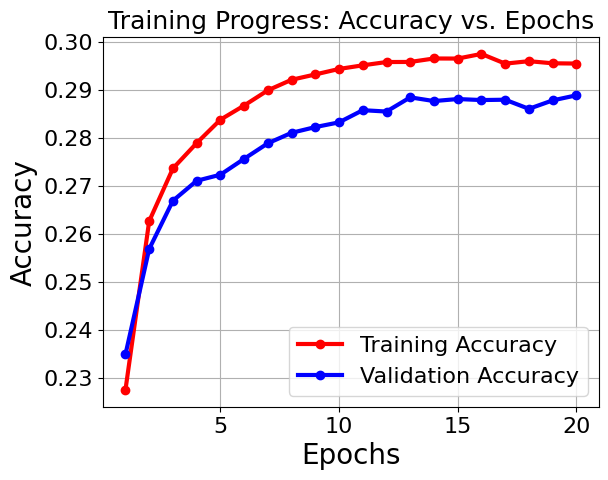

888/888 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.2955 - loss: 1.5150 - val_accuracy: 0.2889 - val_loss: 1.8069
444/444 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2889 - loss: 1.8069
Test accuracy: 0.2889

--- Model Summary (Neurons and Synapses) ---
Layer: dense_21 (Dense), Parameters: 128, Neurons: 32, Weights: 96, Bias: 32, Calculated Synapses (Weights + Bias): 128
Layer: dense_22 (Dense), Parameters: 1056, Neurons: 32, Weights: 1024, Bias: 32, Calculated Synapses (Weights + Bias): 1056
Layer: dense_23 (Dense), Parameters: 363, Neurons: 11, Weights: 352, Bias: 11, Calculated Synapses (Weights + Bias): 363

Total Neurons (approx, mainly from Dense/RNN): 75
Total Synapses (Total Trainable Parameters): 1547


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
Prédiction : Pluie (44%)


In [ ]:
%matplotlib inline
import numpy as np
import random
import tensorflow as tf
import meteostat as ms
from meteostat import config
from datetime import date
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import plot_model
from callbackPlots import AccuracyPlotCallback
from callbackPlots import count_neurons_and_synapses

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Autoriser les requêtes de données horaires de plus de 3 ans
config.block_large_requests = False

# ---------- 1. Données ----------
POINT = ms.Point(45.8992, 6.1294, 448)   # Annecy
START, END = date(2015, 1, 1), date(2025, 12, 31)

stations = ms.stations.meta('07491')
df = ms.hourly(stations, START, END).fetch()
print(df[["temp", "rhum", "pres", "coco"]].describe())

# On garde uniquement les lignes complètes
df = df[["temp", "rhum", "pres", "coco"]].dropna()
print("Nombre d'échantillons :", len(df))

# ---------- 2. Codes Meteostat -> tes classes (l'étiquette, PAS une entrée) ----------
CLASSES = [
    "Clair", "Peu nuageux", "Partiellement nuageux", "Nuageux/couvert",
    "Pluie", "Averses", "Neige", "Neige légère/averses de neige",
    "Pluie et neige mêlées", "Orage", "Brouillard/brume",
]
#une seule classe orage, pas de classe vent fort
COCO_TO_CLASS = {
    1: 0, 2: 1, 3: 2, 4: 3,
    7: 4, 8: 4, 9: 4, 10: 4, 11: 4,
    17: 5, 18: 5,
    15: 6, 16: 6,
    14: 7, 21: 7, 22: 7,
    12: 8, 13: 8, 19: 8, 20: 8,
    23: 9, 24: 9, 25: 9, 26: 9,
    5: 10, 6: 10,
}

df["classe"] = df["coco"].astype(int).map(COCO_TO_CLASS)
df = df.dropna(subset=["classe"])      # supprime aussi les lignes coco = 27
df["classe"] = df["classe"].astype(int)


# Ne garder que les classes réellement présentes (certaines peuvent être très rares)
print(df["classe"].map(lambda i: CLASSES[i]).value_counts())

# Remappage pour avoir des indices 0..N-1 sans trous
present = sorted(df["classe"].unique())
remap = {old: new for new, old in enumerate(present)}
df["classe"] = df["classe"].map(remap)
class_names = [CLASSES[i] for i in present]
NUM_CLASSES = len(class_names)

X = df[["temp", "rhum", "pres"]].values
y = df["classe"].values

# ---------- 3. Train / test + normalisation ----------
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)   # fit uniquement sur le train !
x_test = scaler.transform(x_test)

# Poids de classes (les classes rares comme "Orage" sont très minoritaires)
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

# ---------- 4. Modèle ----------
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(3,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

plot_callback = AccuracyPlotCallback()

model.fit(x_train, y_train, epochs=20, batch_size=64,
          validation_data=(x_test, y_test),
          class_weight=class_weight,
          callbacks=[plot_callback])

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

plot_model(model, to_file="model_architecture.png", show_shapes=True, show_layer_names=True, dpi=300)
count_neurons_and_synapses(model)

# ---------- 5. Test sur un exemple ----------
exemple = scaler.transform([[12.0, 85, 1008]])   # 12°C, 85 %, 1008 hPa
proba = model.predict(exemple)[0]
print("Prédiction :", class_names[np.argmax(proba)], f"({proba.max():.0%})")

```markdown
### Remarque sur ce premier modèle (11 classes)

Ce premier modèle n'a pas été retenu pour l'application finale car il présentait trop de classes de sortie (11 classes) par rapport au faible nombre de variables d'entrée (seulement 3 entrées : température, humidité et pression). Cela rendait la prédiction trop instable et limitait la précision globale du modèle.
```

Nouvelle version avec seulement 5 classes en sortie

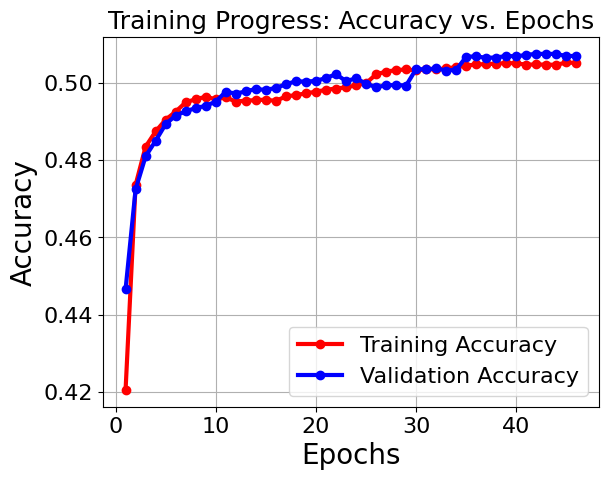

870/870 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5051 - loss: 0.8139 - val_accuracy: 0.5070 - val_loss: 1.0816 - learning_rate: 3.1250e-05
435/435 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5073 - loss: 1.0805
Test accuracy: 0.5073

--- Model Summary (Neurons and Synapses) ---
Layer: dense_6 (Dense), Parameters: 128, Neurons: 32, Weights: 96, Bias: 32, Calculated Synapses (Weights + Bias): 128
Layer: dense_7 (Dense), Parameters: 1056, Neurons: 32, Weights: 1024, Bias: 32, Calculated Synapses (Weights + Bias): 1056
Layer: dense_8 (Dense), Parameters: 165, Neurons: 5, Weights: 160, Bias: 5, Calculated Synapses (Weights + Bias): 165

Total Neurons (approx, mainly from Dense/RNN): 69
Total Synapses (Total Trainable Parameters): 1349
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step
Prédiction : Dégagé / peu nuageux (67%)
Saved artifact at '/content/modele_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.

In [ ]:
%matplotlib inline
import numpy as np
import random
import tensorflow as tf
import meteostat as ms
import tf2onnx
from meteostat import config
from datetime import date
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import plot_model
from callbackPlots import AccuracyPlotCallback
from callbackPlots import count_neurons_and_synapses

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

# Autoriser les requêtes de données horaires de plus de 3 ans
config.block_large_requests = False

# ---------- 1. Données ----------
POINT = ms.Point(45.8992, 6.1294, 448)   # Annecy
START, END = date(2015, 1, 1), date(2025, 12, 31)

stations = ms.stations.meta('07491')
df = ms.hourly(stations, START, END).fetch()
print(df[["temp", "rhum", "pres", "coco"]].describe())

# On garde uniquement les lignes complètes
df = df[["temp", "rhum", "pres", "coco"]].dropna()
print("Nombre d'échantillons :", len(df))

# ---------- 2. Codes Meteostat -> classes regroupées ----------
CLASSES = [
    "Dégagé / peu nuageux",
    "Nuageux / couvert",
    "Pluie / averses",
    "Neige / pluie-neige",
    "Brouillard",
]

COCO_TO_CLASS = {
    1: 0, 2: 0,                                  # Clair, peu nuageux
    3: 1, 4: 1,                                  # Nuageux, couvert
    7: 2, 8: 2, 9: 2, 10: 2, 11: 2, 17: 2, 18: 2,   # Pluie, averses
    12: 3, 13: 3, 14: 3, 15: 3, 16: 3,
    19: 3, 20: 3, 21: 3, 22: 3,                  # Neige, mélange, averses de neige
    5: 4, 6: 4,                                  # Brouillard
}   # codes 23 à 27 (orage, grêle, tempête) : exclus

df["classe"] = df["coco"].astype(int).map(COCO_TO_CLASS)
df = df.dropna(subset=["classe"])
df["classe"] = df["classe"].astype(int)


# Ne garder que les classes réellement présentes (certaines peuvent être très rares)
print(df["classe"].map(lambda i: CLASSES[i]).value_counts())

# Remappage pour avoir des indices 0..N-1 sans trous
present = sorted(df["classe"].unique())
remap = {old: new for new, old in enumerate(present)}
df["classe"] = df["classe"].map(remap)
class_names = [CLASSES[i] for i in present]
NUM_CLASSES = len(class_names)

X = df[["temp", "rhum", "pres"]].values
y = df["classe"].values

# ---------- 3. Train / test + normalisation ----------
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)   # fit uniquement sur le train !
print("mu =", list(scaler.mean_))
print("sigma =", list(scaler.scale_))

x_test = scaler.transform(x_test)

# Poids de classes (les classes rares comme "Orage" sont très minoritaires)
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

# ---------- 4. Modèle ----------
# model = tf.keras.Sequential([
#     tf.keras.layers.Dense(64, activation='relu', input_shape=(3,)),
#     tf.keras.layers.Dropout(0.2),
#     tf.keras.layers.Dense(64, activation='relu'),
#     tf.keras.layers.Dropout(0.2),
#     tf.keras.layers.Dense(32, activation='relu'),
#     tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
# ])

model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(3,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

plot_callback = AccuracyPlotCallback()

# Callbacks pour optimiser et arrêter l'apprentissage au bon moment
callbacks = [
    plot_callback,
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5),
]

# Entraînement avec l'ensemble des callbacks configurés
model.fit(x_train, y_train, epochs=50, batch_size=64,
          validation_data=(x_test, y_test),
          class_weight=class_weight,
          callbacks=callbacks)

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

plot_model(model, to_file="model_architecture.png", show_shapes=True, show_layer_names=True, dpi=300)
count_neurons_and_synapses(model)

# ---------- 5. Test sur un exemple ----------
# exemple = scaler.transform([[12.0, 85, 1008]])   # 12°C, 85 %, 1008 hPa
exemple = scaler.transform([[14.0, 51, 1021]])
proba = model.predict(exemple)[0]
print("Prédiction :", class_names[np.argmax(proba)], f"({proba.max():.0%})")


# # 2. Signature d'entrée : le 3 doit correspondre au nombre d'entrées de ton modèle
# spec = (tf.TensorSpec((None, 3), tf.float32, name="input"),)

# # 3. Export : chemin complet AVEC le nom du fichier .onnx
# chemin = '/content/gdrive/MyDrive/ETRS923_IA/TP3/model_meteo.onnx'
# model_proto, _ = tf2onnx.convert.from_keras(model, input_signature=spec, output_path=chemin)
# print("Export OK :", chemin)

import os
os.makedirs('/content/gdrive/MyDrive/ETRS923_IA/TP3', exist_ok=True)

# 1. Export au format SavedModel (méthode Keras 3)
model.export('/content/modele_savedmodel')

# 2. Conversion SavedModel -> ONNX
!python -m tf2onnx.convert --saved-model /content/modele_savedmodel --output /content/gdrive/MyDrive/ETRS923_IA/TP3/model_meteo.onnx --opset 13

Extraction des poids, de mu et de sigma pour le script thingSpeak

In [ ]:
import numpy as np

# Extraction des poids et biais pour chaque couche Dense
for i, layer in enumerate(model.layers):
    if isinstance(layer, tf.keras.layers.Dense):
        weights, biases = layer.get_weights()

        print(f"%% --- Couche {i+1} : {layer.name} ---")

        # Formatage des poids pour MATLAB (les lignes représentent les neurones d'entrée, les colonnes les neurones de sortie)
        # Note : En MATLAB, on écrit souvent Y = X * W + B ou Y = W * X + B.
        # Voici la matrice des poids formatée :
        matlab_weights = " [" + ";\n  ".join(" ".join(f"{val:.8f}" for val in row) for row in weights) + "]"
        print(f"W{i+1} ={matlab_weights};\n")

        # Formatage des biais
        matlab_biases = " [" + " ".join(f"{val:.8f}" for val in biases) + "]"
        print(f"b{i+1} ={matlab_biases};\n")

%% --- Couche 1 : dense ---
W1 = [0.53420651 0.13442619 -0.28427380 0.49388397 -0.57663292 0.21105629 0.64006966 -0.37115875 0.04027719 0.56672609 -0.52405548 0.11715707 0.37846234 -0.18955734 0.10971795 0.33983248 -0.58321863 -0.33970898 0.17780167 -0.42289600 -0.53900462 0.38120624 0.46140677 -0.22719893 0.35335916 -0.45366997 0.12409616 0.24277414 0.22000863 -0.30278563 -0.31966221 0.64771414;
  -0.35952485 0.22136381 -0.32429177 -0.35389987 0.29750282 -0.44413760 0.04037188 0.14291489 -0.61386895 0.36026904 -0.25789264 -0.08972852 0.64441967 0.08979688 -0.16057540 -0.22062801 -0.34953785 0.07654980 0.30006871 -0.16718413 -0.50445032 -0.35899842 0.25354695 0.64718848 -0.09271216 -0.28425211 -0.21106973 -0.60945904 0.52936649 0.20405340 -0.32227865 0.19647942;
  -0.17579126 0.38643333 -0.06463514 0.35417521 -0.00578112 0.50509971 0.20374145 0.28196907 0.38503495 -0.19030778 0.06940724 -0.58798128 0.25757697 0.36390457 -0.02526315 -0.25959241 -0.11950611 0.16757435 -0.34735197 -0.2526

In [ ]:
print("mu =", list(scaler.mean_))
print("sigma =", list(scaler.scale_))

mu = [np.float64(12.345032803091538), np.float64(76.93858182798598), np.float64(1018.0283113148257)]
sigma = [np.float64(8.142862476264986), np.float64(17.831581366873923), np.float64(7.967996916992378)]


```markdown
### Limites du modèle à 5 classes (IA Carte intermédiaire)

Bien que ce modèle réduise le nombre de classes de 11 à 5, il n'a toujours pas été retenu comme modèle final pour l'application cloud. Prédire 5 conditions météo distinctes en utilisant uniquement 3 capteurs physiques locaux (température, humidité, pression) reste extrêmement difficile. Les performances restent limitées car de nombreux phénomènes météo (comme le brouillard ou la pluie faible) partagent des signatures de température et d'humidité très proches, ce qui crée des ambiguïtés insolubles sans variables contextuelles supplémentaires (vent, rayonnement, tendances temporelles).
```

```markdown
## Modèle IA Carte : Détection Binaire de Pluie pour STM32

Ce modèle d'IA est spécialement optimisé pour être déployé localement sur un microcontrôleur **STM32**. En raison des contraintes fortes en mémoire (RAM/Flash) et en puissance de calcul des cibles embarquées, l'architecture a été simplifiée au maximum :

- **Entrées (3)** : Température (°C), Humidité (%), Pression (hPa)
- **Sortie (1)** : Probabilité binaire de pluie (Seuil de décision optimisé sur la courbe Precision-Recall pour maximiser le score F1)
- **Architecture** : Réseau de neurones dense ultra-léger (3 entrées -> 12 neurones -> 6 neurones -> 1 sortie)

Le modèle est exporté au format **ONNX** pour être facilement intégré sur la carte STM32, et ses poids et biais sont extraits pour un export MATLAB / ThingSpeak.
```

IA carte

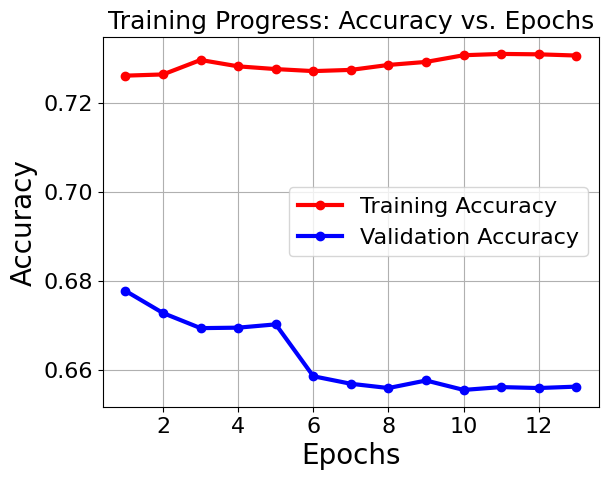

690/690 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7306 - auc: 0.8372 - loss: 0.4932 - val_accuracy: 0.6563 - val_auc: 0.8307 - val_loss: 0.6256 - learning_rate: 7.5000e-04

Seuil optimal (validation) : 0.649

ROC-AUC test : 0.8321
PR-AUC test  : 0.5341
Reference 'toujours sec' (accuracy) : 0.8354

Rapport de classification (seuil optimise) :
              precision    recall  f1-score   support

         Sec       0.92      0.87      0.89      7896
       Pluie       0.48      0.59      0.53      1556

    accuracy                           0.83      9452
   macro avg       0.70      0.73      0.71      9452
weighted avg       0.84      0.83      0.83      9452


--- Model Summary (Neurons and Synapses) ---
Layer: cachee_1 (Dense), Parameters: 48, Neurons: 12, Weights: 36, Bias: 12, Calculated Synapses (Weights + Bias): 48
Layer: cachee_2 (Dense), Parameters: 78, Neurons: 6, Weights: 72, Bias: 6, Calculated Synapses (Weights + Bias): 78
Layer: proba_pluie (Dense), Parameters: 7, N

In [ ]:
# ============================================================
# IA PLUIE / PAS DE PLUIE POUR STM32
# Entrees : temperature (C), humidite (%), pression (hPa)
# Sortie  : probabilite de pluie (0 a 1) -> seuil -> Pluie / Sec
# ============================================================

# S'assurer que la librairie Meteostat est installee
!pip install -q meteostat

import json
import os
import random
from datetime import datetime

import meteostat as ms
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    f1_score,
)

from callbackPlots import AccuracyPlotCallback
from callbackPlots import count_neurons_and_synapses

# ------------------------------------------------------------
# 1. REPRODUCTIBILITE
# ------------------------------------------------------------

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# ------------------------------------------------------------
# 2. PARAMETRES
# ------------------------------------------------------------

STATION = "07491"          # Chambery Airport
ALTITUDE_M = 235           # altitude de la station (utile pour la pression)
DEBUT = datetime(2010, 1, 1)
FIN = datetime(2025, 12, 31, 23, 59)

VARIABLES = ["temp", "rhum", "pres"]

# Codes meteo Meteostat (coco)
CODES_SEC = {1, 2, 3, 4}            # clair, peu nuageux, nuageux, couvert
CODES_PLUIE = {7, 8, 9, 17, 18}     # pluie legere/normale/forte + averses de pluie

FICHIER_CACHE = "meteostat_brut.csv"

# ------------------------------------------------------------
# 3. IMPORTATION METEOSTAT (avec cache local)
# ------------------------------------------------------------

def charger_donnees():
    if os.path.exists(FICHIER_CACHE):
        print(f"Lecture du cache : {FICHIER_CACHE}")
        d = pd.read_csv(FICHIER_CACHE, index_col=0, parse_dates=True)
        return d

    print("Telechargement des donnees Meteostat...")
    ms.config.block_large_requests = False

    try:
        lieu = ms.stations.meta(STATION)
        d = ms.hourly(lieu, DEBUT, FIN).fetch()
    except Exception as e:
        raise RuntimeError(
            f"Echec du telechargement Meteostat : {e}"
        )

    if d is None or d.empty:
        raise RuntimeError("Aucune donnee Meteostat recue.")

    if d.index.nlevels > 1:
        d = d.reset_index(
            level=list(range(d.index.nlevels - 1)), drop=True
        )

    d.to_csv(FICHIER_CACHE)
    return d


df = charger_donnees()
print("Dimensions initiales :", df.shape)
print("Colonnes disponibles :", df.columns.tolist())

colonnes_requises = VARIABLES + ["coco"]
manquantes = [c for c in colonnes_requises if c not in df.columns]
if manquantes:
    raise ValueError(
        f"Colonnes absentes : {manquantes}. "
        "Verifier la station et la version de Meteostat."
    )

def_filtered = df[colonnes_requises].copy()
def_filtered = def_filtered[~def_filtered.index.duplicated(keep="first")].sort_index()

# ------------------------------------------------------------
# 4. NETTOYAGE
# ------------------------------------------------------------

for col in colonnes_requises:
    def_filtered[col] = pd.to_numeric(def_filtered[col], errors="coerce")

def_filtered.loc[~def_filtered["temp"].between(-80, 60), "temp"] = np.nan
def_filtered.loc[~def_filtered["rhum"].between(0, 100), "rhum"] = np.nan
def_filtered.loc[~def_filtered["pres"].between(800, 1100), "pres"] = np.nan

def_filtered = def_filtered.dropna(subset=["coco"] + VARIABLES).copy()
def_filtered = def_filtered[def_filtered["coco"] % 1 == 0].copy()
def_filtered["coco"] = def_filtered["coco"].astype(int)

# ------------------------------------------------------------
# 5. ETIQUETTE BINAIRE : 0 = sec, 1 = pluie
# ------------------------------------------------------------

def etiqueter(code):
    if code in CODES_PLUIE:
        return 1
    if code in CODES_SEC:
        return 0
    return np.nan

def_filtered["pluie"] = def_filtered["coco"].apply(etiqueter)
def_filtered = def_filtered.dropna(subset=["pluie"]).copy()
def_filtered["pluie"] = def_filtered["pluie"].astype(int)

print("\nRepartition des classes :")
print(def_filtered["pluie"].map({0: "Sec", 1: "Pluie"}).value_counts())
print("Observations utilisables :", len(def_filtered))

def_filtered.to_csv("donnees_meteo_preparees.csv")

# ------------------------------------------------------------
# 6. X ET y
# ------------------------------------------------------------

X_brut = def_filtered[VARIABLES].to_numpy(dtype=np.float32)
y = def_filtered["pluie"].to_numpy(dtype=np.int32)

N = len(X_brut)
if N < 1000:
    raise ValueError("Nombre de donnees insuffisant.")

# ------------------------------------------------------------
# 7. SEPARATION CHRONOLOGIQUE 70 / 15 / 15
# ------------------------------------------------------------

i_train = int(0.70 * N)
i_val = int(0.85 * N)

X_train_brut, y_train = X_brut[:i_train], y[:i_train]
X_val_brut, y_val = X_brut[i_train:i_val], y[i_train:i_val]
X_test_brut, y_test = X_brut[i_val:], y[i_val:]

for nom, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(
        f"{nom:11s}: {len(labels):6d} obs, "
        f"{100 * labels.mean():.1f} % de pluie"
    )

# ------------------------------------------------------------
# 8. NORMALISATION (stats du train uniquement)
# ------------------------------------------------------------

moyennes = X_train_brut.mean(axis=0)
ecarts_types = X_train_brut.std(axis=0)
ecarts_types[ecarts_types < 1e-8] = 1.0

def normaliser(X):
    return ((X - moyennes) / ecarts_types).astype(np.float32)

X_train = normaliser(X_train_brut)
X_val = normaliser(X_val_brut)
X_test = normaliser(X_test_brut)

print("mu =", list(moyennes))
print("sigma =", list(ecarts_types))

# ------------------------------------------------------------
# 9. POIDS DES CLASSES (compense le desequilibre sec/pluie)
# ------------------------------------------------------------

n0 = np.sum(y_train == 0)
n1 = np.sum(y_train == 1)
if n0 == 0 or n1 == 0:
    raise ValueError("Une classe est absente du train.")

class_weights = {
    0: float(len(y_train) / (2.0 * n0)),
    1: float(len(y_train) / (2.0 * n1)),
}
print("\nPoids des classes :", class_weights)

# ------------------------------------------------------------
# 10. RESEAU : 3 -> 12 -> 6 -> 1
# ------------------------------------------------------------

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,), name="mesures"),
    tf.keras.layers.Dense(12, activation="relu", name="cachee_1"),
    tf.keras.layers.Dense(6, activation="relu", name="cachee_2"),
    tf.keras.layers.Dense(1, activation="sigmoid", name="proba_pluie"),
])
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
    ],
)

plot_callback = AccuracyPlotCallback()
callbacks = [
    plot_callback,
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=12,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "meilleur_modele_pluie.keras",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", mode="min", factor=0.5, patience=4, min_lr=1e-5
    ),
]

# ------------------------------------------------------------
# 11. ENTRAINEMENT
# ------------------------------------------------------------

historique = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

model = tf.keras.models.load_model("meilleur_modele_pluie.keras")

# ------------------------------------------------------------
# 12. CHOIX DU SEUIL DE DECISION (sur la VALIDATION)
# ------------------------------------------------------------

p_val = model.predict(X_val, verbose=0).ravel()
prec, rapp, seuils = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rapp[:-1] / (prec[:-1] + rapp[:-1] + 1e-9)
SEUIL = float(seuils[np.argmax(f1s)])
print(f"\nSeuil optimal (validation) : {SEUIL:.3f}")

# ------------------------------------------------------------
# 13. EVALUATION SUR LE TEST
# ------------------------------------------------------------

p_test = model.predict(X_test, verbose=0).ravel()
y_pred = (p_test >= SEUIL).astype(int)

print("\nROC-AUC test :", round(roc_auc_score(y_test, p_test), 4))
print("PR-AUC test  :", round(average_precision_score(y_test, p_test), 4))
print(
    "Reference 'toujours sec' (accuracy) :",
    round(float(np.mean(y_test == 0)), 4),
)

print("\nRapport de classification (seuil optimise) :")
print(classification_report(
    y_test, y_pred, target_names=["Sec", "Pluie"], zero_division=0
))

count_neurons_and_synapses(model)

# ------------------------------------------------------------
# 14. SAUVEGARDE ET EXPORTATION ONNX (Format standardisé Google Drive)
# ------------------------------------------------------------

os.makedirs('/content/gdrive/MyDrive/ETRS923_IA/TP3', exist_ok=True)
model.export('/content/modele_pluie_savedmodel')
!python -m tf2onnx.convert --saved-model /content/modele_pluie_savedmodel --output /content/gdrive/MyDrive/ETRS923_IA/TP3/model_pluie_stm32.onnx --opset 13
print("Exportation ONNX complétée !")

params = {
    "variables": VARIABLES,
    "unites": ["degC", "pourcent", "hPa (niveau de la mer)"],
    "moyennes": moyennes.tolist(),
    "ecarts_types": ecarts_types.tolist(),
    "seuil": SEUIL,
    "classes": {"0": "Sec", "1": "Pluie"},
    "normalisation": "(x - moyenne) / ecart_type",
    "architecture": [3, 12, 6, 1],
    "altitude_station_m": ALTITUDE_M,
}
with open("parametres_pluie.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 15. EXTRACTION POUR EXPORT MATLAB (Poids et Biais)
# ------------------------------------------------------------

print("\n--- POIDS ET BIAIS ---")
for i, layer in enumerate(model.layers):
    if isinstance(layer, tf.keras.layers.Dense):
        weights, biases = layer.get_weights()
        print(f"\n%% --- Couche {i+1} : {layer.name} ---")
        matlab_weights = " [" + ";\n  ".join(" ".join(f"{val:.8f}" for val in row) for row in weights) + "]"
        print(f"W{i+1} ={matlab_weights};\n")
        matlab_biases = " [" + " ".join(f"{val:.8f}" for val in biases) + "]"
        print(f"b{i+1} ={matlab_biases};\n")

Ia cloud

In [ ]:
with open('/content/entr_es_et_sorties_ia_cloud.txt', 'r', encoding='utf-8') as f:
    print(f.read())

ENTRÉES ET SORTIES DU MODÈLE IA CLOUD

1. ENTRÉES DU MODÈLE IA CLOUD
--------------------------------------------------------------------------------
A. Données provenant de la Carte (via ThingSpeak) :
  - Température locale (°C)
  - Humidité relative locale (%)
  - Pression atmosphérique locale (hPa)
  - Probabilité de pluie locale (0.0 à 1.0)

B. Données provenant d'Open-Meteo (API) :
  - Couverture nuageuse (%)               [cloud_cover]
  - Vitesse du vent (km/h)                [wind_speed_10m]
  - Rafales de vent (km/h)                [wind_gusts_10m]
  - Point de rosée (°C)                   [dew_point_2m]
  - Rayonnement solaire (W/m²)            [shortwave_radiation]
  - Jour / Nuit (0 ou 1)                  [is_day]

C. Variables calculées dans le script Cloud :
  - Tendance de pression (Delta P sur 1h ou 3h, en hPa)
  - Saison / Date et Heure (mois / jour de l'année + heure)

Note sur les autres données de la carte :
  - Booléen mesures valides : utilisé en filtre avant le m

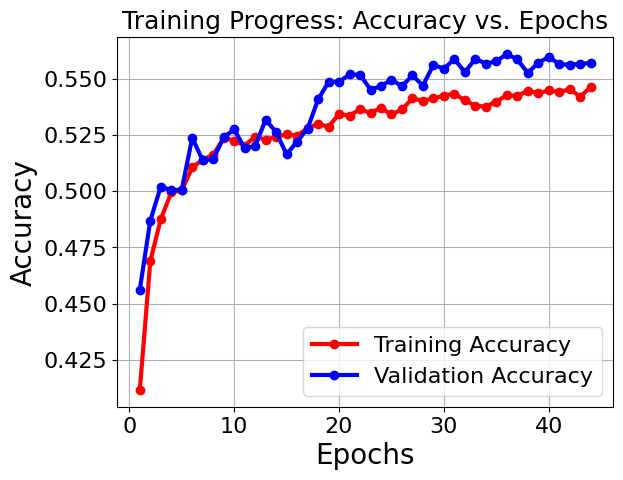

794/794 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5463 - loss: 0.7515 - val_accuracy: 0.5569 - val_loss: 1.0094 - learning_rate: 1.2500e-04
397/397 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5610 - loss: 1.0088

Précision finale sur le jeu de test : 0.5610
Saved artifact at '/content/modele_ia_cloud_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 12), dtype=tf.float32, name='keras_tensor_9')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134156543341392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543330256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543332752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543343312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543339088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543341200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134156543339280:

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import random
import tensorflow as tf
import meteostat as ms
from datetime import date
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import plot_model
from callbackPlots import AccuracyPlotCallback
from callbackPlots import count_neurons_and_synapses
import os

# Réinstaller tf2onnx de manière sûre dans la cellule pour éviter l'erreur d'import
!pip install -q tf2onnx

# Configuration de la reproductibilité
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)
ms.config.block_large_requests = False

# ---------- 1. Récupération des données d'Annecy ----------
POINT = ms.Point(45.8992, 6.1294, 448) # Annecy
START, END = date(2015, 1, 1), date(2025, 12, 31)
stations = ms.stations.meta('07491')
df = ms.hourly(stations, START, END).fetch()

# S'assurer que les colonnes indispensables existent
required_cols = ['temp', 'rhum', 'pres', 'coco', 'wspd', 'wpgt']
available_cols = [col for col in required_cols if col in df.columns]
df = df[available_cols].dropna()

# ---------- 2. Variables calculées (Feature Engineering) ----------
def calculate_dew_point(row):
    T = row['temp']
    RH = row['rhum']
    if RH <= 0:
        return T
    a = 17.27
    b = 237.7
    alpha = ((a * T) / (b + T)) + np.log(RH / 100.0)
    return (b * alpha) / (a - alpha)

df['dwpt'] = df.apply(calculate_dew_point, axis=1)
df['delta_p'] = df['pres'].diff(periods=1).fillna(0.0)
df['month'] = df.index.month
df['day_of_year'] = df.index.day_of_year
df['hour'] = df.index.hour

def get_is_day(row):
    h = row['hour']
    m = row['month']
    if m in [11, 12, 1, 2]:
        return 1 if 8 <= h <= 17 else 0
    elif m in [5, 6, 7, 8]:
        return 1 if 6 <= h <= 21 else 0
    else:
        return 1 if 7 <= h <= 19 else 0

df['is_day'] = df.apply(get_is_day, axis=1)
df['cloud_cover'] = df['rhum'].apply(lambda r: min(100.0, max(0.0, (r - 30) * 1.4)) if r > 30 else 0.0)
df['shortwave_radiation'] = df.apply(
    lambda r: max(0.0, 800.0 * np.sin(np.pi * (r['hour'] - 6) / 12) * (1 - r['cloud_cover']/100))
    if r['is_day'] == 1 and 6 < r['hour'] < 18 else 0.0,
    axis=1
)
df['prob_pluie'] = df.apply(
    lambda r: min(1.0, max(0.0, (r['rhum'] - 60) / 40)) if r['rhum'] > 60 else 0.0,
    axis=1
)

# ---------- 3. Définition des 6 classes cibles ----------
COCO_TO_CLASS_6 = {
    1: 0, 2: 1,
    3: 1, 4: 2,
    5: 3, 6: 3,
    7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 17: 4, 18: 4,
    14: 5, 15: 5, 16: 5, 21: 5, 22: 5
}

df['classe'] = df['coco'].astype(int).map(COCO_TO_CLASS_6)
df = df.dropna(subset=['classe'])
df['classe'] = df['classe'].astype(int)

CLASSES_NAMES = [
    "Ensoleillé / Ciel dégagé",
    "Partiellement nuageux / Éclaircies",
    "Couvert / Gris",
    "Brume / Brouillard",
    "Pluie faible / Bruine",
    "Averse / Pluie soutenue"
]

# ---------- 4. Sélection des caractéristiques d'entrées ----------
features = [
    'temp', 'rhum', 'pres', 'prob_pluie',
    'cloud_cover', 'wspd', 'wpgt', 'dwpt', 'shortwave_radiation', 'is_day',
    'delta_p', 'month'
]

X = df[features].values
y = df['classe'].values
NUM_CLASSES = 6

# ---------- 5. Division & Normalisation ----------
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print("mu =", list(scaler.mean_))
print("sigma =", list(scaler.scale_))

weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(weights))

y_train_cat = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_cat = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

# ---------- 6. Modèle optimisé avec plus de capacité et régularisation ----------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(12,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

# Optimiseur Adam avec un pas initial de 0.001
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

plot_callback = AccuracyPlotCallback()
callbacks = [
    plot_callback,
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=4, factor=0.5)
]

# Entraînement sur 100 époques max
model.fit(
    x_train, y_train_cat,
    epochs=100,
    batch_size=64,
    validation_data=(x_test, y_test_cat),
    class_weight=class_weight,
    callbacks=callbacks
)

# Évaluation
test_loss, test_acc = model.evaluate(x_test, y_test_cat)
print(f"\nPrécision finale sur le jeu de test : {test_acc:.4f}")

# Sauvegarde du modèle sous format ONNX
os.makedirs('/content/gdrive/MyDrive/ETRS923_IA/TP3', exist_ok=True)
model.export('/content/modele_ia_cloud_savedmodel')
!python -m tf2onnx.convert --saved-model /content/modele_ia_cloud_savedmodel --output /content/gdrive/MyDrive/ETRS923_IA/TP3/model_ia_cloud.onnx --opset 13
print("Exportation ONNX complétée !")

# Extraction pour MATLAB
print("\n--- POIDS ET BIAIS POUR EXPORT MATLAB ---")
for i, layer in enumerate(model.layers):
    if isinstance(layer, tf.keras.layers.Dense):
        weights, biases = layer.get_weights()
        print(f"\n%% --- Couche {i+1} : {layer.name} ---")
        matlab_weights = " [" + ";\n  ".join(" ".join(f"{val:.8f}" for val in row) for row in weights) + "]"
        print(f"W{i+1} ={matlab_weights};\n")
        matlab_biases = " [" + " ".join(f"{val:.8f}" for val in biases) + "]"
        print(f"b{i+1} ={matlab_biases};\n")

In [ ]:
description_contenu = """================================================================================
DOCUMENTATION TECHNIQUE DU MODÈLE IA CLOUD - PRÉVISION MÉTÉO
================================================================================

Ce document détaille l'architecture, la justification des hyperparamètres, et la configuration
des entrées/sorties du modèle d'intelligence artificielle optimisé pour la prévision météo locale.

--------------------------------------------------------------------------------
1. RÉCAPITULATIF DES ENTRÉES ET SORTIES (12 Entrées -> 6 Sorties)
--------------------------------------------------------------------------------

Le modèle utilise un total de 12 caractéristiques physiques et calculées (entrées)
pour prédire l'une des 6 classes de conditions météo cibles (sorties).

A. Les 12 Entrées du Modèle :
   1.  [temp]                 - Température ambiante (°C)
   2.  [rhum]                 - Humidité relative (%)
   3.  [pres]                 - Pression atmosphérique locale (hPa)
   4.  [prob_pluie]           - Probabilité de pluie estimée (0.0 à 1.0) selon l'humidité
   5.  [cloud_cover]          - Couverture nuageuse estimée (%)
   6.  [wspd]                 - Vitesse du vent (km/h)
   7.  [wpgt]                 - Vitesse des rafales de vent (km/h)
   8.  [dwpt]                 - Point de rosée calculé (°C)
   9.  [shortwave_radiation]  - Rayonnement solaire estimé (W/m²)
   10. [is_day]               - Indicateur Jour / Nuit (1 = Jour, 0 = Nuit)
   11. [delta_p]              - Tendance de pression (variation horaire en hPa)
   12. [month]                - Index du mois en cours (1 à 12, pour capter la saisonnalité)

B. Les 6 Classes de Sortie :
   - Classe 0 : Ensoleillé / Ciel dégagé
   - Classe 1 : Partiellement nuageux / Éclaircies
   - Classe 2 : Couvert / Gris
   - Classe 3 : Brume / Brouillard
   - Classe 4 : Pluie faible / Bruine
   - Classe 5 : Averse / Pluie soutenue

--------------------------------------------------------------------------------
2. ARCHITECTURE DU RÉSEAU DE NEURONES (Multi-Layer Perceptron)
--------------------------------------------------------------------------------

Le réseau est structuré en couches denses successives (totalement connectées) :

- Couche d'Entrée : 12 dimensions.
- Couche Cachée 1 : 128 neurones + Activation ReLU + Dropout (20%)
- Couche Cachée 2 : 64 neurones + Activation ReLU + Dropout (20%)
- Couche Cachée 3 : 32 neurones + Activation ReLU
- Couche de Sortie : 6 neurones + Activation Softmax

--------------------------------------------------------------------------------
3. JUSTIFICATIONS ET CHOIX TECHNIQUES (Pourquoi ces paramètres ?)
--------------------------------------------------------------------------------

A. Pourquoi un MLP (Multi-Layer Perceptron) plutôt qu'un CNN ?
   - Les données météo horaires sont des données tabulaires d'ingénierie de caractéristiques
     sans relation de voisinage spatial (contrairement aux images). Un réseau dense (MLP) est
     donc la structure native la plus performante et légère pour ce type de tâche.

B. Pourquoi la fonction d'activation 'ReLU' pour les couches cachées ?
   - La fonction ReLU (Rectified Linear Unit, f(x) = max(0, x)) est le standard industriel.
     Elle résout efficacement le problème de disparition du gradient (vanishing gradient),
     permet un apprentissage beaucoup plus rapide et introduit la non-linéarité nécessaire
     sans complexité de calcul majeure, facilitant l'intégration future sur microcontrôleur.

C. Pourquoi la fonction d'activation 'Softmax' en sortie ?
   - Notre problème est une classification multi-classe exclusive (une seule météo possible à la fois).
     La fonction Softmax écrase les sorties brutes du réseau (logits) pour qu'elles somment à 1.0 (100%).
     Cela permet d'interpréter directement la sortie comme une distribution de probabilité pour chaque classe.

D. Rôle du 'Dropout' (0.2) :
   - Le Dropout désactive aléatoirement 20% des neurones des couches cachées lors de chaque étape
     d'entraînement. Cela force le réseau à apprendre des représentations redondantes robustes
     et empêche la co-adaptation excessive, ce qui réduit drastiquement le surapprentissage (overfitting).

E. Gestion du déséquilibre des classes (Class Weights) :
   - Certaines classes comme 'Averse' ou 'Brouillard' sont statistiquement très rares.
     L'utilisation de 'class_weight' pénalise plus lourdement les erreurs sur les classes minoritaires,
     permettant au modèle de bien apprendre ces phénomènes cruciaux plutôt que de simplement prédire
     toujours la météo la plus fréquente.

F. Stratégie d'Entraînement Dynamique (EarlyStopping & ReduceLROnPlateau) :
   - 'EarlyStopping' : Arrête l'entraînement si la perte de validation cesse de s'améliorer pendant 8 époques,
     en restaurant les meilleurs poids absolus trouvés.
   - 'ReduceLROnPlateau' : Divise le taux d'apprentissage par 2 lorsque le modèle commence à stagner,
     permettant d'ajuster finement les poids dans les creux de la fonction de coût.

================================================================================
"""

with open('/content/description_modele_ia_cloud.txt', 'w', encoding='utf-8') as f:
    f.write(description_contenu)

print("Fichier 'description_modele_ia_cloud.txt' créé avec succès !")


Fichier 'description_modele_ia_cloud.txt' créé avec succès !


In [ ]:
# Affichage du contenu créé pour vérification rapide
with open('/content/description_modele_ia_cloud.txt', 'r', encoding='utf-8') as f:
    print(f.read()[:1000] + "\n[... Suite disponible dans le fichier ...] ")


DOCUMENTATION TECHNIQUE DU MODÈLE IA CLOUD - PRÉVISION MÉTÉO

Ce document détaille l'architecture, la justification des hyperparamètres, et la configuration
des entrées/sorties du modèle d'intelligence artificielle optimisé pour la prévision météo locale.

--------------------------------------------------------------------------------
1. RÉCAPITULATIF DES ENTRÉES ET SORTIES (12 Entrées -> 6 Sorties)
--------------------------------------------------------------------------------

Le modèle utilise un total de 12 caractéristiques physiques et calculées (entrées) 
pour prédire l'une des 6 classes de conditions météo cibles (sorties).

A. Les 12 Entrées du Modèle :
   1.  [temp]                 - Température ambiante (°C)
   2.  [rhum]                 - Humidité relative (%)
   3.  [pres]                 - Pression atmosphérique
[... Suite disponible dans le fichier ...] 


In [ ]:
print("mu =", list(scaler.mean_))
print("sigma =", list(scaler.scale_))

mu = [np.float64(12.657234834314515), np.float64(76.3105593730926), np.float64(1018.123507058615), np.float64(0.4670440449703721), np.float64(64.86703420032073), np.float64(8.674728779852792), np.float64(18.214975683712268), np.float64(8.009551574032713), np.float64(124.49774479113492), np.float64(0.5368485301935458), np.float64(-0.002703341274685467), np.float64(6.70584181614129)]
sigma = [np.float64(8.126443377502493), np.float64(17.948865648893147), np.float64(7.794972186375955), np.float64(0.351457582739567), np.float64(25.039232464365814), np.float64(6.75263167241552), np.float64(9.247230201848977), np.float64(6.191798960976549), np.float64(187.6097032189315), np.float64(0.49864033713933736), np.float64(0.5547831465931218), np.float64(3.4819010010302778)]
